# 03 — Exploratory Data Analysis

**Stage 3 of the Tier A pipeline.** Hypothesis-driven: one section per branch of the Stage 0 issue
tree (`01` §0.4) that EDA can speak to. Every chart carries an **Action Title** and a written
**So What** and **Implication** beneath it. Branch B (are the segments real?) and branch D (the
target) need the clustering and belong to `05`; formal tests with effect sizes are `04`'s job.

| Branch | Question | Exhibit |
|---|---|---|
| **A. The file** | What does the pair construction look like, and what kind of number is the score? | ex01, ex02 |
| **C1. Income** | Does income drive spending? | ex03 |
| **C2. Age** | Does age drive spending? | ex04 |
| **C3. Gender** | Does gender drive spending? | ex05 |

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd()
while not (ROOT / "archive" / "Mall_Customers.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
ARCHIVE = ROOT / "archive"
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
REPORTS, FIGS, MODELS = ROOT / "reports", ROOT / "reports" / "figures", ROOT / "models"
for p in (RAW, PROC, REPORTS, FIGS, MODELS):
    p.mkdir(parents=True, exist_ok=True)

KF_PATH = REPORTS / "_key_figures.json"


def _plain(v):
    if isinstance(v, dict):
        return {str(k): _plain(x) for k, x in v.items()}
    if hasattr(v, "item"):
        return v.item()
    if isinstance(v, (list, tuple)):
        return [_plain(x) for x in v]
    return v


def kf_update(**kw):
    """Append to reports/_key_figures.json — the only place the report reads numbers from."""
    kf = json.loads(KF_PATH.read_text()) if KF_PATH.exists() else {}
    kf.update({k: _plain(v) for k, v in kw.items()})
    KF_PATH.write_text(json.dumps(kf, indent=1, sort_keys=True))
    print(f"  _key_figures.json <- {', '.join(kw)}  ({len(kf)} figures total)")

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# ---------------------------------------------------------------------------------------------
# DESIGN.md palette, defined inline (no local module imports — a fresh clone must run as-is).
#
# Validated with the dataviz skill's checker rather than eyeballed:
#   node scripts/validate_palette.js "#2251FF,#008A7E,#C1841C,#00A9F4" --mode light --pairs all
#     PASS lightness | PASS chroma floor | PASS CVD separation (worst pair dE 12.5 protan)
#     PASS normal-vision separation (18.3) | WARN contrast: Cyan 2.56:1 on white
# The Cyan WARN obliges relief: every segment is direct-labelled AND has its own marker shape,
# and the report carries the profile as a table. DESIGN.md's Teal #00857C FAILS the chroma floor
# (C = 0.097 < 0.10, reads as grey), so it is nudged to #008A7E on the same hue.
# Grey is context ink only (the Mainstream segment); Navy is text ink only — never a series fill.
# ---------------------------------------------------------------------------------------------
NAVY, BLUE, TEAL, AMBER, CYAN = "#051C2C", "#2251FF", "#008A7E", "#C1841C", "#00A9F4"
SLATE, GREY, GRID, LIGHT = "#7F93A6", "#9FADB8", "#E9ECEF", "#D5DCE2"

# Semantic mapping, fixed once and used in every notebook (fixed order Blue → Teal → Amber → Cyan):
SEGMENTS = ["Under-engaged Affluent", "Affluent Spenders", "Young Enthusiasts",
            "Budget Conscious", "Mainstream"]
SEG_COLORS = {"Under-engaged Affluent": BLUE,    # the conversion question — the emphasis story
              "Affluent Spenders": TEAL,         # the core to retain
              "Young Enthusiasts": AMBER,
              "Budget Conscious": CYAN,
              "Mainstream": GREY}                # context
SEG_MARKERS = {"Under-engaged Affluent": "o", "Affluent Spenders": "s", "Young Enthusiasts": "^",
               "Budget Conscious": "D", "Mainstream": "."}
C_FOCUS, C_SECOND, C_REF, C_CONTEXT = BLUE, TEAL, AMBER, GREY


def apply_style():
    mpl.rcParams.update({
        "figure.dpi": 130, "savefig.dpi": 130, "figure.facecolor": "white",
        "axes.facecolor": "white", "savefig.facecolor": "white",
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 9, "text.color": NAVY,
        "axes.titlelocation": "left", "axes.titlesize": 10.5, "axes.titleweight": "bold",
        "axes.titlecolor": NAVY, "axes.titlepad": 10,
        "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GREY,
        "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
        "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
        "grid.color": GRID, "grid.linewidth": 0.8, "axes.grid": True, "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 8.5,
        "lines.linewidth": 2.0, "lines.markersize": 8,
    })


apply_style()
SOURCE = "Mall_Customers.csv (Kaggle 'Mall Customer Segmentation Data', 200 loyalty members)"


def finish(fig, note=""):
    """Every exhibit carries its source line — STRUCTURE.md Step 7.3. Placed under the lowest
    artist (axis labels, outside legends), so it never collides with them."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    y0 = min(ax.get_tightbbox(r).transformed(fig.transFigure.inverted()).y0 for ax in fig.axes)
    fig.text(0.005, y0 - 0.12 / fig.get_figheight(), f"Source: {SOURCE}" + (f" · {note}" if note else ""),
             fontsize=7, color=SLATE, ha="left", va="top")


def suptitle(fig, text, y=1.04):
    fig.suptitle(text, x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=y)


def save(fig, name):
    fig.savefig(FIGS / name, bbox_inches="tight", facecolor="white")
    print(f"  saved reports/figures/{name}")

df = pd.read_parquet(PROC / "mall_clean.parquet")
print(f"{len(df)} members, {df.shape[1]} columns")

200 members, 21 columns


## 3.1 Branch A — the file

**Hypothesis (Stage 0):** the file is a clean snapshot of a member base. `01` §1.5 already showed it was
generated in income-sorted pairs. The exhibit makes that visible, because it decides what Part I of the
report can claim.

In [2]:
pairs = (df.sort_values("customer_id")
           .assign(twin=lambda d: np.where(d.id_odd, "odd", "even"))
           .pivot(index="pair_id", columns="twin", values="score")
           .join(df.groupby("pair_id").income_k.first()))
pairs["gap"] = (pairs["even"] - pairs["odd"]).abs()
print(pairs.groupby(pd.cut(pairs.income_k, [0, 40, 69, 200]), observed=True).gap.describe().round(1))

           count  mean   std   min   25%   50%   75%   max
income_k                                                  
(0, 40]     25.0  53.4  23.3   0.0  37.0  57.0  69.0  88.0
(40, 69]    37.0   8.1   6.1   1.0   4.0   7.0  11.0  33.0
(69, 200]   38.0  63.3  14.7  36.0  50.2  64.5  73.0  88.0


### Exhibit 1 — Every income is shared by two members; at both extremes one twin spends and the other does not

  saved reports/figures/ex01_construction.png


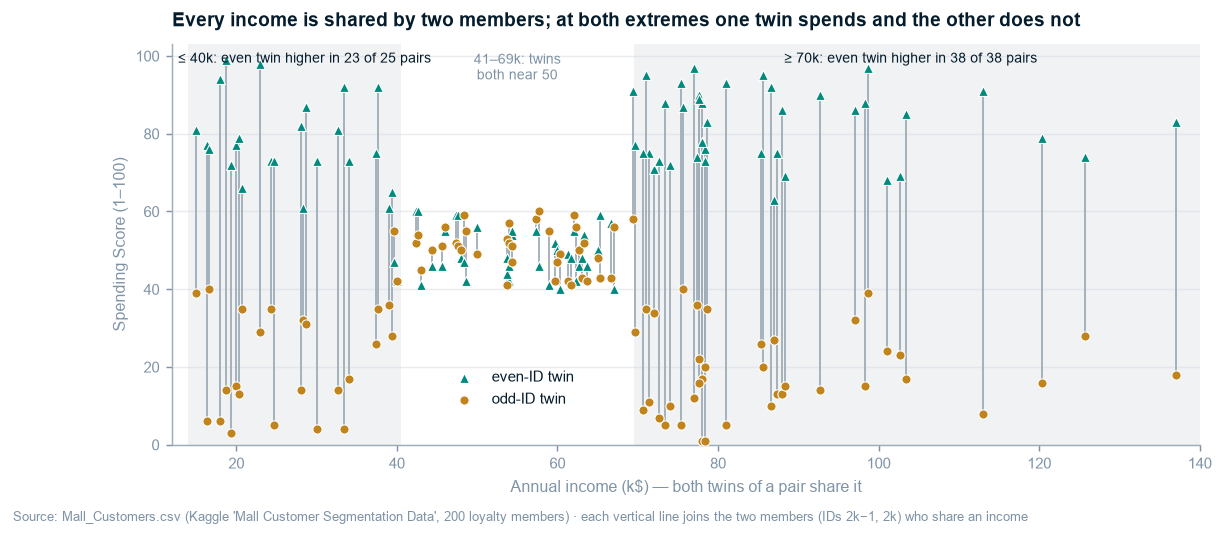

In [3]:
fig, ax = plt.subplots(figsize=(10.2, 4.0))
for b0, b1 in [(14, 40.5), (69.5, 140)]:
    ax.axvspan(b0, b1, color=LIGHT, alpha=0.35, lw=0)
jit = (pairs.index.to_numpy() % 3 - 1) * 0.35          # separate pairs that share an income value
x = pairs.income_k.to_numpy() + jit
ax.vlines(x, pairs[["odd", "even"]].min(axis=1), pairs[["odd", "even"]].max(axis=1), color=GREY, lw=1.0, zorder=1)
ax.scatter(x, pairs["even"], s=30, marker="^", color=TEAL, edgecolor="white", lw=0.6, zorder=3,
           label="even-ID twin")
ax.scatter(x, pairs["odd"], s=26, marker="o", color=AMBER, edgecolor="white", lw=0.6, zorder=3,
           label="odd-ID twin")
ax.set_xlim(12, 140); ax.set_ylim(0, 103)
ax.set_xlabel("Annual income (k$) — both twins of a pair share it"); ax.set_ylabel("Spending Score (1–100)")
ext = pairs[(pairs.income_k <= 40) | (pairs.income_k >= 70)]
ax.text(28.5, 101, f"≤ 40k: even twin higher in {(pairs.loc[pairs.income_k <= 40, 'even'] > pairs.loc[pairs.income_k <= 40, 'odd']).sum()} of {(pairs.income_k <= 40).sum()} pairs",
        ha="center", va="top", fontsize=8, color=NAVY)
ax.text(104, 101, f"≥ 70k: even twin higher in {(pairs.loc[pairs.income_k >= 70, 'even'] > pairs.loc[pairs.income_k >= 70, 'odd']).sum()} of {(pairs.income_k >= 70).sum()} pairs",
        ha="center", va="top", fontsize=8, color=NAVY)
ax.text(55, 101, "41–69k: twins\nboth near 50", ha="center", va="top", fontsize=8, color=SLATE)
ax.legend(loc="lower center", ncol=1, bbox_to_anchor=(0.33, 0.06))
ax.set_title("Every income is shared by two members; at both extremes one twin spends and the other does not")
finish(fig, "each vertical line joins the two members (IDs 2k−1, 2k) who share an income")
save(fig, "ex01_construction.png")
plt.show()

**So What:** the four "corner" groups that every analysis of this file finds (rich/poor × spender/saver)
were filled one twin at a time. Above 70k income the odd-ID twin scores at most 40 and the even-ID twin
at least 63, with no exception. That is a generator, not a mall.

**Implication:** the *shape* of the segments is usable; their *sizes* are not. Part I of the report
must say so before any segment count is quoted, and the recommendation must re-measure sizes on the
real member base.

### Exhibit 2 — Members skew young, incomes are mid-range, and the score is spread flat — it is a rank, not a spend

  saved reports/figures/ex02_distributions.png


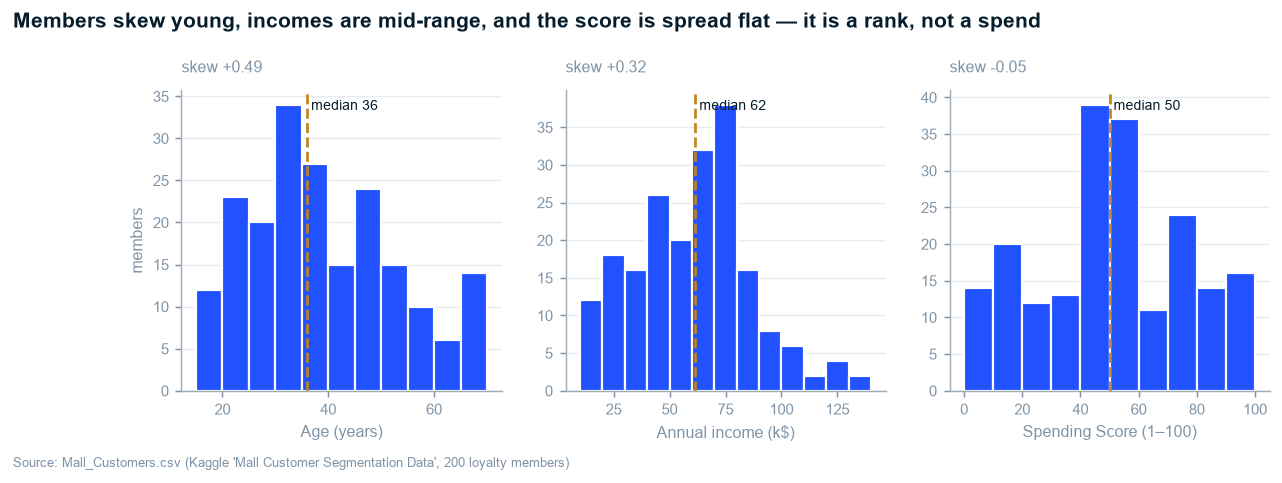

          count  mean   std   min   25%   50%   75%    max
age       200.0  38.8  14.0  18.0  28.8  36.0  49.0   70.0
income_k  200.0  60.6  26.3  15.0  41.5  61.5  78.0  137.0
score     200.0  50.2  25.8   1.0  34.8  50.0  73.0   99.0


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.0), sharey=False)
specs = [("age", "Age (years)", np.arange(15, 75, 5)), ("income_k", "Annual income (k$)", np.arange(10, 145, 10)),
         ("score", "Spending Score (1–100)", np.arange(0, 105, 10))]
for ax, (col, lbl, bins) in zip(axes, specs):
    ax.hist(df[col], bins=bins, color=BLUE, edgecolor="white", lw=1.2)
    m = df[col].median()
    ax.axvline(m, color=AMBER, lw=1.5, ls="--")
    ax.text(m, ax.get_ylim()[1] * 0.97, f" median {m:.0f}", color=NAVY, fontsize=8, va="top")
    ax.set_xlabel(lbl); ax.set_title(f"skew {df[col].skew():+.2f}", fontsize=9, fontweight="normal", color=SLATE)
axes[0].set_ylabel("members")
suptitle(fig, "Members skew young, incomes are mid-range, and the score is spread flat — it is a rank, not a spend", y=1.08)
finish(fig)
save(fig, "ex02_distributions.png")
plt.show()
print(df[["age", "income_k", "score"]].describe().round(1).T)

**So What:** no column needs a transformation (all |skew| < 0.5), so standardising is enough for
clustering. The score's flat shape is the second clue, after the pairs, that it is a constructed rank:
real spending is right-skewed, with a long tail of big spenders.

**Implication:** any statement such as "Affluent Spenders spend 4.8× more" would be wrong. A score of 82
against 17 is a ranking gap, not a spending ratio. The report quotes score points, never multiples.

## 3.2 Branch C1 — income

**Hypothesis (Stage 0, from the review):** income does not drive spending (r = 0.01).

In [5]:
band = df.groupby("income_band", observed=True).score.agg(["size", "mean", "std", "min", "max"]).round(1)
print(band)
print(f"\nPearson r(income, score) = {df.income_k.corr(df.score):.3f}")

             size  mean   std  min  max
income_band                            
≤ 40k          50  49.5  30.2    3   99
41–69k         74  50.6   7.6   40   91
≥ 70k          76  50.3  33.4    1   97

Pearson r(income, score) = 0.010


### Exhibit 3 — Income does not set how much members spend; it sets how much their spending varies

  saved reports/figures/ex03_income_spread.png


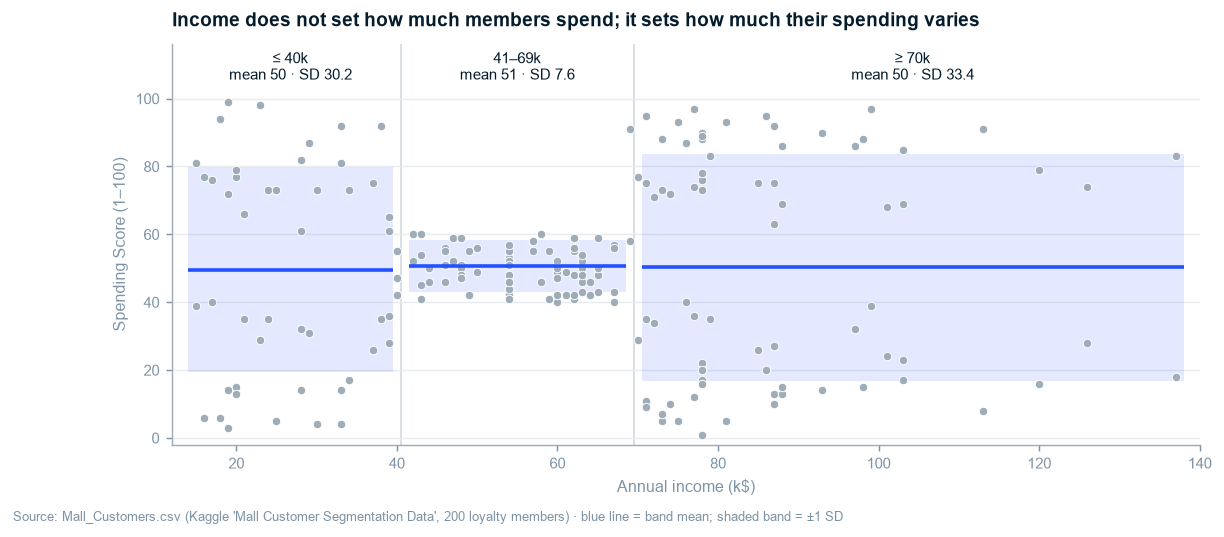

In [6]:
fig, ax = plt.subplots(figsize=(10.2, 4.0))
edges = {"≤ 40k": (13, 40.5), "41–69k": (40.5, 69.5), "≥ 70k": (69.5, 139)}
ax.scatter(df.income_k, df.score, s=22, color=GREY, edgecolor="white", lw=0.5, zorder=2)
for b, (x0, x1) in edges.items():
    m, s = band.loc[b, "mean"], band.loc[b, "std"]
    ax.fill_between([x0 + 1, x1 - 1], m - s, m + s, color=BLUE, alpha=0.12, lw=0, zorder=1)
    ax.hlines(m, x0 + 1, x1 - 1, color=BLUE, lw=2, zorder=3)
    ax.text((x0 + x1) / 2, 114, f"{b}\nmean {m:.0f} · SD {s:.1f}", ha="center", va="top", fontsize=8.2, color=NAVY)
    if x1 < 139:
        ax.axvline(x1, color=LIGHT, lw=1, zorder=0)
ax.set_xlim(12, 140); ax.set_ylim(-2, 116)
ax.set_xlabel("Annual income (k$)"); ax.set_ylabel("Spending Score (1–100)")
ax.set_title("Income does not set how much members spend; it sets how much their spending varies")
finish(fig, "blue line = band mean; shaded band = ±1 SD")
save(fig, "ex03_income_spread.png")
plt.show()

**So What:** the review's "income alone does not predict spending" is right about the *level*: every
band averages ~50. It misses the *spread*. In the middle band (41–69k) almost everyone scores 40–60;
at both ends members split into big spenders and non-spenders. r = 0.01 hides a strong, non-linear
dependence, which `04` tests directly (distance correlation).

**Implication:** income tells marketing *where targeting matters*. In the middle band one broad
message fits nearly everyone. At the extremes the same income holds opposite behaviours, so the
offer must be chosen by score, not income.

## 3.3 Branch C2 — age

**Hypothesis (Stage 0, from the review):** age has a modest negative relationship with score (r = −0.33).

In [7]:
print(df.groupby("age_group", observed=True).score.agg(["size", "mean", "max"]).round(1))
ct = pd.crosstab(df.age_over_40, df.score > 60)
print("\nscore > 60  by  age > 40:\n", ct)
for b in df.income_band.cat.categories:
    s = df[(df.income_band == b) & df.age_over_40]
    print(f"  {b:7s}: max score among over-40s = {s.score.max()}  (n = {len(s)})")

           size  mean  max
age_group                 
18–25        38  54.9   94
26–35        60  64.4   99
36–45        36  44.8   95
46–55        37  36.7   59
56+          29  38.4   60

score > 60  by  age > 40:
 score        False  True 
age_over_40              
False           60     62
True            78      0
  ≤ 40k  : max score among over-40s = 55  (n = 15)
  41–69k : max score among over-40s = 60  (n = 42)
  ≥ 70k  : max score among over-40s = 39  (n = 21)


### Exhibit 4 — No member over 40 scores above 60: high spending is an under-40 behaviour in this file

  saved reports/figures/ex04_age_ceiling.png


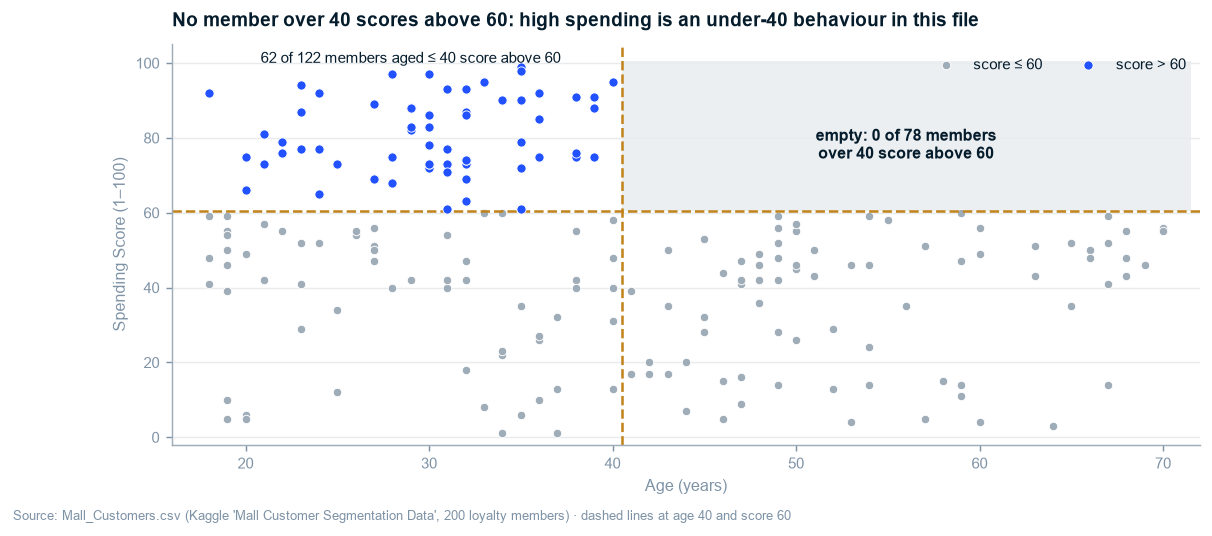

In [8]:
fig, ax = plt.subplots(figsize=(10.2, 4.0))
hi = df.score > 60
ax.add_patch(plt.Rectangle((40.5, 60.5), 31, 40, color=LIGHT, alpha=0.45, lw=0, zorder=0))
ax.scatter(df.loc[~hi, "age"], df.loc[~hi, "score"], s=22, color=GREY, edgecolor="white", lw=0.5, zorder=2,
           label="score ≤ 60")
ax.scatter(df.loc[hi, "age"], df.loc[hi, "score"], s=26, color=BLUE, edgecolor="white", lw=0.5, zorder=3,
           label="score > 60")
ax.axvline(40.5, color=AMBER, lw=1.4, ls="--"); ax.axhline(60.5, color=AMBER, lw=1.4, ls="--")
n_old = int(df.age_over_40.sum()); n_young_hi = int((hi & ~df.age_over_40).sum())
ax.text(56, 78, f"empty: 0 of {n_old} members\nover 40 score above 60", ha="center", va="center",
        fontsize=9, color=NAVY, fontweight="bold")
ax.text(29, 103, f"{n_young_hi} of {int((~df.age_over_40).sum())} members aged ≤ 40 score above 60",
        ha="center", va="top", fontsize=8.2, color=NAVY)
ax.set_xlim(16, 72); ax.set_ylim(-2, 105)
ax.set_xlabel("Age (years)"); ax.set_ylabel("Spending Score (1–100)")
ax.legend(loc="upper right", ncol=2)
ax.set_title("No member over 40 scores above 60: high spending is an under-40 behaviour in this file")
finish(fig, "dashed lines at age 40 and score 60")
save(fig, "ex04_age_ceiling.png")
plt.show()

**So What:** "r = −0.33" undersells it. Age does not lower the score gradually: it puts a **ceiling**
on it. Over 40, nobody scores above 60, at any income (checked band by band above). Under 40, half do.
Because age and income are uncorrelated (r = −0.01), this is not income in disguise.

**Implication:** this reshapes the conversion question. The high-income, low-score group mixes
under-40s, who have high-scoring peers of the same age and income, with over-40s, who have none
anywhere in the file. A campaign that needs a 50-year-old to behave like an Affluent Spender is betting
on a member the data never shows. `05` splits the convert target at 40.

## 3.4 Branch C3 — gender

**Hypothesis (Stage 0):** gender makes little difference (review: 51.5 vs 48.5).

In [9]:
print(df.groupby("gender", observed=True).score.describe().round(1))

        count  mean   std  min   25%   50%   75%   max
gender                                                
Female  112.0  51.5  24.1  5.0  35.0  50.0  73.0  99.0
Male     88.0  48.5  27.9  1.0  24.5  50.0  70.0  97.0


### Exhibit 5 — Women and men score within 3 points of each other, across the whole range

  saved reports/figures/ex05_gender.png


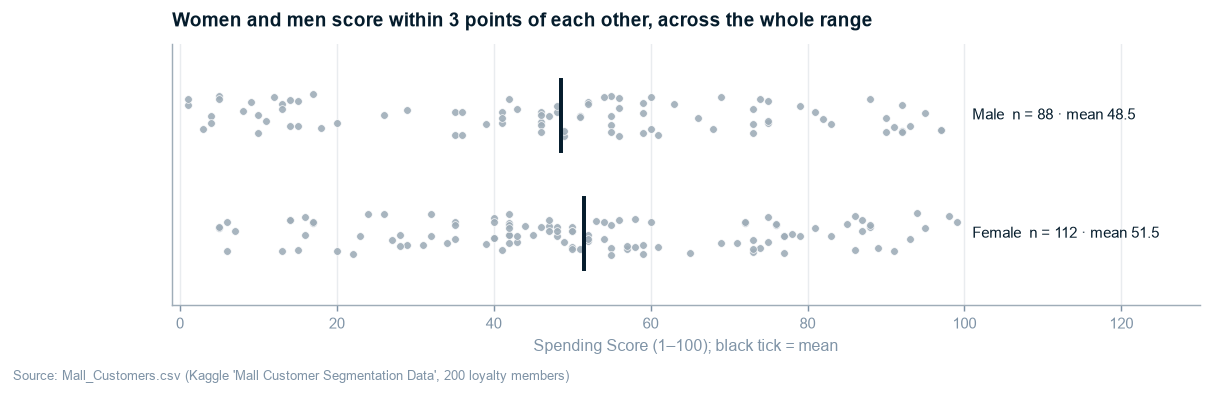

In [10]:
fig, ax = plt.subplots(figsize=(10.2, 2.6))
rng = np.random.default_rng(RANDOM_STATE)
for i, (gname, col) in enumerate([("Female", GREY), ("Male", GREY)]):
    s = df.loc[df.gender == gname, "score"]
    ax.scatter(s, i + rng.uniform(-0.18, 0.18, len(s)), s=18, color=col, edgecolor="white", lw=0.4, alpha=0.9)
    ax.plot([s.mean()] * 2, [i - 0.3, i + 0.3], color=NAVY, lw=2.2)
    ax.text(101, i, f"{gname}  n = {len(s)} · mean {s.mean():.1f}", va="center", fontsize=8.5, color=NAVY)
ax.set_yticks([]); ax.set_xlim(-1, 130); ax.set_ylim(-0.6, 1.6)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Spending Score (1–100); black tick = mean")
ax.set_title("Women and men score within 3 points of each other, across the whole range")
finish(fig)
save(fig, "ex05_gender.png")
plt.show()

**So What:** the two distributions overlap almost completely. `04` puts a number on it (an effect
size with a confidence interval), but nothing here would justify a gender-specific campaign.

**Implication:** gender is used only as a fairness check on the segments (`05`), never to target.

In [11]:
kf_update(
    band_sd={b: float(band.loc[b, "std"]) for b in band.index},
    band_mean={b: float(band.loc[b, "mean"]) for b in band.index},
    band_n={b: int(band.loc[b, "size"]) for b in band.index},
    n_over_40=int(df.age_over_40.sum()), n_under_40=int((~df.age_over_40).sum()),
    n_over_40_hi=int((df.age_over_40 & (df.score > 60)).sum()),
    n_under_40_hi=int((~df.age_over_40 & (df.score > 60)).sum()),
    n_score_over_60=int((df.score > 60).sum()),
    age_band_mean_score={str(k): float(v) for k, v in df.groupby("age_group", observed=True).score.mean().items()},
    score_mean_female=float(df.loc[df.gender == "Female", "score"].mean()),
    score_mean_male=float(df.loc[df.gender == "Male", "score"].mean()),
    hi_income_odd_max=int(pairs.loc[pairs.income_k >= 70, "odd"].max()),
    hi_income_even_min=int(pairs.loc[pairs.income_k >= 70, "even"].min()),
)

  _key_figures.json <- band_sd, band_mean, band_n, n_over_40, n_under_40, n_over_40_hi, n_under_40_hi, n_score_over_60, age_band_mean_score, score_mean_female, score_mean_male, hi_income_odd_max, hi_income_even_min  (46 figures total)


## Ghost deck — updated after EDA

| Stage 0 expectation | After EDA |
|---|---|
| Part I: "This file can [/cannot] size segments" | **Cannot.** Pair construction fills the corners one twin at a time (ex01) |
| Part III: "Income does not set spending" | **Half right.** It does not set the level; it sets the spread (ex03) |
| Part III: "Age matters" | **Stronger than expected.** A hard ceiling at 40, not a slope (ex04) |
| Part III: "Gender does not" | **Confirmed** (ex05), to be quantified in `04` |
| Part IV: "Under-engaged Affluent = biggest upside" | **To be split at age 40** in `05`: only the under-40s have high-spending peers in the data |

## Stage 3 — Gate Checklist

- [x] Profile reviewed (`01` §1.3–1.4 plus ex02); no automated profiler needed for 5 columns
- [x] Each Stage 0 hypothesis EDA can address has an analysis (A, C1, C2, C3); B and D go to `05`
- [x] Distributions and relationships visualised and annotated · [x] All titles are action titles
- [x] Every finding has a So What and an Implication
- [x] Ghost deck updated (table above)
- [x] Data issues looped back to `02` (the ID's role, pass 2) · [x] Findings documented